## Setting up the imports and CUDA accleration

In [ ]:
# Installing the required packages

#!pip install numpy pandas torch scikit-learn joblib tqdm matplotlib

In [23]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
from tqdm import tqdm
import matplotlib.pyplot as plt
import warnings
import multiprocessing
warnings.filterwarnings('ignore')

# Enable CUDA debugging
os.environ['TORCH_USE_CUDA_DSA'] = '1'  # Enable device-side assertions
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'  # Better error reporting

In [24]:
# CPU/GPU configuration
def setup_device():
    """Set up device with proper error handling and CPU fallback"""
    print("Setting up computation device...")
    if torch.cuda.is_available():
        try:
            # Test CUDA with a simple tensor operation
            test_tensor = torch.zeros(5, 5).cuda()
            test_result = test_tensor + 1
            torch.cuda.empty_cache()
            print(f"CUDA is working properly. Using GPU: {torch.cuda.get_device_name(0)}")
            return torch.device('cuda')
        except Exception as e:
            print(f"CUDA error detected: {e}")
            print("Falling back to CPU with multi-core support.")

            # Set up CPU with multiple cores
            num_cores = multiprocessing.cpu_count()
            torch.set_num_threads(num_cores)
            print(f"Using CPU with {num_cores} cores.")
            return torch.device('cpu')
    else:
        # Set up CPU with multiple cores
        num_cores = multiprocessing.cpu_count()
        torch.set_num_threads(num_cores)
        print(f"CUDA not available. Using CPU with {num_cores} cores.")
        return torch.device('cpu')

# Set device
device = setup_device()
print(f"Using device: {device}")

# Helper functions for GPU memory management
def print_gpu_memory():
    """Print GPU memory usage stats"""
    if torch.cuda.is_available():
        used = torch.cuda.memory_allocated() / (1024**3)
        total = torch.cuda.get_device_properties(0).total_memory / (1024**3)
        print(f"GPU memory: {used:.2f}GB used out of {total:.2f}GB total")

def clear_gpu_memory():
    """Clear GPU memory cache"""
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        print("GPU memory cleared")

Setting up computation device...
CUDA is working properly. Using GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Using device: cuda


## Preprocessing the Data

In [25]:
# Load datasets
df_bat = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_features_dr.csv')
df_bowl = pd.read_csv(r'D:\ED\statModel\required data\all_league_bowl_features_dr.csv')
df_bat_fp = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_fp.csv')
df_bowl_fp = pd.read_csv(r'D:\ED\statModel\required data\all_league_bowl_fp.csv')
df_bat_matchup = pd.read_csv(r'D:\ED\statModel\required data\all_league_bat_matchup.csv')

# Merge dataframes
df_bat = df_bat.merge(
    df_bat_fp[['batting_fp', 'match_id', 'batter_id']],
    on=['match_id', 'batter_id'],
    how='left'
)

df_bowl = df_bowl.merge(
    df_bowl_fp[['bowling_fp', 'match_id', 'bowler_id']],
    on=['match_id', 'bowler_id'],
    how='left'
)

df_bat = df_bat.merge(
    df_bat_matchup[['match_id', 'batter_id', 'batter_matchup_score']],
    on=['match_id', 'batter_id'],
    how='left'
)

# IMPORTANT: Split by season to prevent temporal data leakage
train_bat = df_bat[df_bat['season'] < 2023].copy()
test_bat = df_bat[df_bat['season'] >= 2023].copy()
train_bowl = df_bowl[df_bowl['season'] < 2023].copy()
test_bowl = df_bowl[df_bowl['season'] >= 2023].copy()

print(f"Batting training set: {len(train_bat)} samples")
print(f"Batting test set: {len(test_bat)} samples")
print(f"Bowling training set: {len(train_bowl)} samples")
print(f"Bowling test set: {len(test_bowl)} samples")

Batting training set: 124899 samples
Batting test set: 35569 samples
Bowling training set: 124945 samples
Bowling test set: 36096 samples


## Encoding Categorical Features

In [26]:
def encode_categorical_features(train_df, test_df, categorical_cols):
    """
    Encode categorical features properly WITHOUT data leakage

    Args:
        train_df: Training dataframe
        test_df: Testing dataframe
        categorical_cols: List of categorical column names

    Returns:
        train_df: Transformed training dataframe
        test_df: Transformed testing dataframe
        encoders: Dictionary of label encoders
        cat_indices: List of categorical column indices
        num_categories: List of number of categories per feature
    """
    encoders = {}
    cat_indices = []
    num_categories = []

    # Get indices of categorical columns
    for col in categorical_cols:
        if col in train_df.columns:
            idx = list(train_df.columns).index(col)
            cat_indices.append(idx)

    # Process each categorical column
    for i, col in enumerate(categorical_cols):
        if col in train_df.columns:
            print(f"Encoding {col} (index {cat_indices[i]})...")

            # CRITICAL FIX: Only fit on training data to prevent leakage
            train_values = train_df[col].fillna('unknown').astype(str)

            # Create and fit encoder
            encoder = LabelEncoder()
            encoder.fit(train_values)

            # Transform train data
            train_df[col] = encoder.transform(train_values)

            # Get number of categories
            n_cats = len(encoder.classes_)
            num_categories.append(n_cats)

            # Store encoder in dictionary
            encoders[col] = encoder

            # Handle unseen categories in test data properly
            test_values = test_df[col].fillna('unknown').astype(str)
            for val in test_values.unique():
                if val not in encoder.classes_:
                    print(f"  - Found unseen category '{val}' in test data")
                    # Replace with a known category
                    test_df.loc[test_df[col] == val, col] = encoder.classes_[0]

            # Transform test data
            test_df[col] = encoder.transform(test_df[col].astype(str))

            # Convert to integer type to ensure compatibility with embeddings
            train_df[col] = train_df[col].astype(int)
            test_df[col] = test_df[col].astype(int)

            # Verify values are in correct range
            min_train = train_df[col].min()
            max_train = train_df[col].max()
            min_test = test_df[col].min()
            max_test = test_df[col].max()

            print(f"  - Encoded {n_cats} unique values")
            print(f"  - Train range: [{min_train}, {max_train}]")
            print(f"  - Test range: [{min_test}, {max_test}]")

            # Verify all values are within range [0, n_cats-1]
            if max_train >= n_cats or min_train < 0 or max_test >= n_cats or min_test < 0:
                print(f"  - Warning: Values outside valid range [0, {n_cats-1}]")
                print(f"  - Clamping values to valid range")

                # Clamp values to valid range
                train_df[col] = np.clip(train_df[col], 0, n_cats-1)
                test_df[col] = np.clip(test_df[col], 0, n_cats-1)

    return train_df, test_df, encoders, cat_indices, num_categories

# Define categorical columns
categorical_cols = ['bat_team', 'bowl_team', 'venue', 'league']

# Encode categorical features
print("Encoding batting data categorical features...")
train_bat, test_bat, bat_encoders, bat_cat_indices, bat_num_cats = encode_categorical_features(
    train_bat, test_bat, categorical_cols
)

print("\nEncoding bowling data categorical features...")
train_bowl, test_bowl, bowl_encoders, bowl_cat_indices, bowl_num_cats = encode_categorical_features(
    train_bowl, test_bowl, categorical_cols
)

# Save the encoders using joblib
joblib.dump(bat_encoders, '../tabTransformer/bat_encoders.joblib')
joblib.dump(bowl_encoders, '../tabTransformer/bowl_encoders.joblib')

Encoding batting data categorical features...
Encoding bat_team (index 4)...
  - Found unseen category 'Paarl Royals' in test data
  - Found unseen category 'MI Cape Town' in test data
  - Found unseen category 'Joburg Super Kings' in test data
  - Found unseen category 'Durban's Super Giants' in test data
  - Found unseen category 'Pretoria Capitals' in test data
  - Found unseen category 'Sunrisers Eastern Cape' in test data
  - Found unseen category 'Dubai Capitals' in test data
  - Found unseen category 'Abu Dhabi Knight Riders' in test data
  - Found unseen category 'MI Emirates' in test data
  - Found unseen category 'Sharjah Warriors' in test data
  - Found unseen category 'Desert Vipers' in test data
  - Found unseen category 'Gulf Giants' in test data
  - Found unseen category 'Texas Super Kings' in test data
  - Found unseen category 'Los Angeles Knight Riders' in test data
  - Found unseen category 'San Francisco Unicorns' in test data
  - Found unseen category 'Washington F

['bowl_encoders.joblib']

In [36]:
def prepare_features_targets(train_df, test_df, is_batting=True, include_target_in_features=False):
    """
    Prepare features and targets without data leakage

    Args:
        train_df: Training dataframe
        test_df: Testing dataframe
        is_batting: Boolean flag for batting/bowling data
        include_target_in_features: Whether to include target column in features

    Returns:
        X_train: Train feature matrix
        y_train: Train target values
        X_test: Test feature matrix
        y_test: Test target values
        feature_cols: Feature column names
        scaler: Fitted StandardScaler object
    """
    # Define target column
    target_col = 'batting_fp' if is_batting else 'bowling_fp'

    # Define columns to exclude
    exclude_cols = ['date', 'match_id', 'batter', 'batter_id'] if is_batting else ['date', 'match_id', 'bowler', 'bowler_id']

    if target_col not in train_df.columns:
        raise ValueError(f"{target_col} not found in the dataframe")

    # Define feature columns
    if include_target_in_features:
        feature_cols = [col for col in train_df.columns if col not in exclude_cols]
    else:
        feature_cols = [col for col in train_df.columns if col not in exclude_cols + [target_col]]

    # Extract features and target
    X_train = train_df[feature_cols].copy()
    y_train = train_df[target_col].copy()
    X_test = test_df[feature_cols].copy()
    y_test = test_df[target_col].copy()

    # Handle missing values
    X_train = X_train.fillna(0)
    X_test = X_test.fillna(0)
    y_train = y_train.fillna(0)
    y_test = y_test.fillna(0)

    # Get indices of categorical columns
    cat_cols = [train_df.columns[idx] for idx in (bat_cat_indices if is_batting else bowl_cat_indices)]
    num_cols = [col for col in feature_cols if col not in cat_cols]

    # CRITICAL FIX: Scale only numeric columns, fit on train, apply to test
    scaler = StandardScaler()
    if num_cols:
        X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
        X_test[num_cols] = scaler.transform(X_test[num_cols])

    # Final check for inf/NaN values
    X_train = X_train.replace([np.inf, -np.inf], 0)
    X_test = X_test.replace([np.inf, -np.inf], 0)

    return X_train.values, y_train.values, X_test.values, y_test.values, feature_cols, scaler

# Prepare features and targets
print("Preparing batting features...")
X_train_bat, y_train_bat, X_test_bat, y_test_bat, bat_feature_cols, bat_scaler = prepare_features_targets(
    train_bat, test_bat, is_batting=True, include_target_in_features=False
)

print("Preparing bowling features...")
X_train_bowl, y_train_bowl, X_test_bowl, y_test_bowl, bowl_feature_cols, bowl_scaler = prepare_features_targets(
    train_bowl, test_bowl, is_batting=False , include_target_in_features=False
)

# Save the scalers
joblib.dump(bat_scaler, '../tabTransformer/bat_scaler.joblib')
joblib.dump(bowl_scaler, '../tabTransformer/bowl_scaler.joblib')

Preparing batting features...
Preparing bowling features...


['bowl_scaler.joblib']

## Defining the TabTransformer Model

In [37]:
class TabTransformer(nn.Module):
    def __init__(self, num_features, cat_dims, num_cats, embed_dim=32,
                 hidden_dim=128, dropout=0.1, n_layers=3):
        super().__init__()

        # Model parameters
        self.num_features = num_features
        self.cat_dims = cat_dims
        self.num_cats = num_cats
        self.embed_dim = embed_dim

        print(f"TabTransformer init: {num_features} features, {len(cat_dims)} categorical features")
        print(f"Categorical dims: {cat_dims}")
        print(f"Number of categories per feature: {num_cats}")

        # Create embeddings for categorical features
        self.embeddings = nn.ModuleList()
        for i, num_cat in enumerate(num_cats):
            # Ensure we have at least 2 categories
            effective_num_cat = max(num_cat, 2)
            self.embeddings.append(nn.Embedding(effective_num_cat, embed_dim))

        # Calculate number of categorical and continuous features
        self.num_cat_features = len(cat_dims)
        self.num_cont_features = num_features - self.num_cat_features
        print(f"Continuous features: {self.num_cont_features}")

        # Linear projection for continuous features
        self.cont_projection = nn.Linear(self.num_cont_features, embed_dim)

        # Calculate total dimension after embedding
        self.total_embed_dim = embed_dim * (self.num_cat_features + 1)
        print(f"Final dimension: {self.total_embed_dim}")

        # Build MLP layers
        layers = []
        input_dim = self.total_embed_dim

        # Hidden layers
        for _ in range(n_layers):
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            input_dim = hidden_dim

        # Output layer
        layers.append(nn.Linear(input_dim, 1))

        # Create sequential model
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        # Process categorical features
        cat_embeddings = []

        for i, embedding_layer in enumerate(self.embeddings):
            if i < len(self.cat_dims):
                # Get categorical index
                cat_idx = self.cat_dims[i]

                if cat_idx < x.shape[1]:
                    # Get categorical values and clamp to valid range
                    cat_vals = x[:, cat_idx].long()
                    max_idx = self.num_cats[i] - 1
                    cat_vals = torch.clamp(cat_vals, 0, max_idx)

                    # Get embeddings
                    emb = embedding_layer(cat_vals)
                    cat_embeddings.append(emb)

        # Process continuous features
        if self.num_cont_features > 0:
            # Get continuous feature indices
            cont_indices = [i for i in range(x.shape[1]) if i not in self.cat_dims]

            # Extract continuous features
            if cont_indices:
                cont_features = x[:, cont_indices]
                cont_embedding = self.cont_projection(cont_features)

                # Combine embeddings
                if cat_embeddings:
                    combined = torch.cat([*cat_embeddings, cont_embedding], dim=1)
                else:
                    combined = cont_embedding
            else:
                # Fallback if indices are wrong
                print("Warning: No continuous feature indices found")
                if cat_embeddings:
                    combined = torch.cat(cat_embeddings, dim=1)
                else:
                    # Should never happen, but just in case
                    combined = torch.zeros(x.shape[0], self.total_embed_dim, device=x.device)
        else:
            # Only categorical features
            if cat_embeddings:
                combined = torch.cat(cat_embeddings, dim=1)
            else:
                # Fallback if no features are processed
                combined = torch.zeros(x.shape[0], self.total_embed_dim, device=x.device)

        # Apply MLP
        output = self.mlp(combined)
        return output.squeeze()

In [38]:
def create_data_loaders(X_train, y_train, X_test, y_test, batch_size=512):
    """Create PyTorch DataLoaders for training and testing"""
    # Safety checks
    X_train = np.nan_to_num(X_train)
    y_train = np.nan_to_num(y_train)
    X_test = np.nan_to_num(X_test)
    y_test = np.nan_to_num(y_test)

    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train)
    y_train_tensor = torch.FloatTensor(y_train)
    X_test_tensor = torch.FloatTensor(X_test)
    y_test_tensor = torch.FloatTensor(y_test)

    # Create datasets
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

    # Create dataloaders with large batch size
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,  # Safer default
        pin_memory=device.type=='cuda'
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        num_workers=0,  # Safer default
        pin_memory=device.type=='cuda'
    )

    return train_loader, test_loader

# Create validation split
def create_validation_split(X, y, val_ratio=0.2):
    """Create validation split without data leakage"""
    n = X.shape[0]
    indices = np.random.permutation(n)
    val_size = int(val_ratio * n)

    train_idx = indices[val_size:]
    val_idx = indices[:val_size]

    X_train = X[train_idx]
    y_train = y[train_idx]
    X_val = X[val_idx]
    y_val = y[val_idx]

    return X_train, y_train, X_val, y_val

# Create data loaders
print("Creating data loaders with batch size 512...")
train_loader_bat, test_loader_bat = create_data_loaders(
    X_train_bat, y_train_bat, X_test_bat, y_test_bat, batch_size=512
)
train_loader_bowl, test_loader_bowl = create_data_loaders(
    X_train_bowl, y_train_bowl, X_test_bowl, y_test_bowl, batch_size=512
)

# Create validation splits
X_train_bat_new, y_train_bat_new, X_val_bat, y_val_bat = create_validation_split(X_train_bat, y_train_bat)
X_train_bowl_new, y_train_bowl_new, X_val_bowl, y_val_bowl = create_validation_split(X_train_bowl, y_train_bowl)

# Create validation data loaders
val_loader_bat_train, val_loader_bat = create_data_loaders(
    X_train_bat_new, y_train_bat_new, X_val_bat, y_val_bat, batch_size=512
)
val_loader_bowl_train, val_loader_bowl = create_data_loaders(
    X_train_bowl_new, y_train_bowl_new, X_val_bowl, y_val_bowl, batch_size=512
)

Creating data loaders with batch size 512...


In [39]:
print("\n=== INITIALIZING MODELS ===")

# Model hyperparameters
embed_dim = 32
hidden_dim = 128
dropout = 0.1
n_layers = 3

# Initialize batting model
print("Initializing batting model...")
model_bat = TabTransformer(
    num_features=X_train_bat.shape[1],
    cat_dims=bat_cat_indices,
    num_cats=bat_num_cats,
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    dropout=dropout,
    n_layers=n_layers
).to(device)

# Initialize bowling model
print("Initializing bowling model...")
model_bowl = TabTransformer(
    num_features=X_train_bowl.shape[1],
    cat_dims=bowl_cat_indices,
    num_cats=bowl_num_cats,
    embed_dim=embed_dim,
    hidden_dim=hidden_dim,
    dropout=dropout,
    n_layers=n_layers
).to(device)


=== INITIALIZING MODELS ===
Initializing batting model...
TabTransformer init: 33 features, 4 categorical features
Categorical dims: [4, 5, 18, 6]
Number of categories per feature: [159, 159, 212, 13]
Continuous features: 29
Final dimension: 160
Initializing bowling model...
TabTransformer init: 32 features, 4 categorical features
Categorical dims: [5, 4, 18, 6]
Number of categories per feature: [159, 159, 212, 13]
Continuous features: 28
Final dimension: 160


## Training theModel

In [40]:
def train_model(model, train_loader, val_loader, epochs=200, lr=0.001, patience=20, model_name="model"):
    """Train model with simplified progress bar and early stopping"""
    print(f"Training {model_name} model...")

    # Initialize optimizer and loss function
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, verbose=True
    )

    # History tracking
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    early_stopping_counter = 0

    # Single progress bar for all epochs
    epoch_bar = tqdm(range(epochs), desc=f"Training {model_name}")

    start_time = time.time()

    for epoch in epoch_bar:
        # Training phase
        model.train()
        epoch_train_loss = 0
        train_batches = 0

        for batch_X, batch_y in train_loader:
            # Move to device
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            # Forward pass
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            # Check for NaN loss
            if torch.isnan(loss) or torch.isinf(loss):
                continue

            # Backward pass
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            # Update metrics
            epoch_train_loss += loss.item()
            train_batches += 1

        # Calculate average training loss
        avg_train_loss = epoch_train_loss / max(train_batches, 1)
        train_losses.append(avg_train_loss)

        # Validation phase
        model.eval()
        epoch_val_loss = 0
        val_batches = 0

        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                # Move to device
                batch_X = batch_X.to(device)
                batch_y = batch_y.to(device)

                # Forward pass
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)

                # Update metrics
                epoch_val_loss += loss.item()
                val_batches += 1

        # Calculate average validation loss
        avg_val_loss = epoch_val_loss / max(val_batches, 1)
        val_losses.append(avg_val_loss)

        # Update learning rate
        scheduler.step(avg_val_loss)

        # Update progress bar with current metrics
        epoch_bar.set_postfix({
            'train_loss': f"{avg_train_loss:.4f}",
            'val_loss': f"{avg_val_loss:.4f}"
        })

        # Early stopping check with patience=20
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            # Save best model
            torch.save(model.state_dict(), f'best_{model_name}_model.pt')
            early_stopping_counter = 0
        else:
            early_stopping_counter += 1

        # Check for early stopping
        if early_stopping_counter >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs")
            break

        # Clean up GPU memory every 10 epochs
        if (epoch + 1) % 10 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Calculate training time
    training_time = time.time() - start_time
    hours, rem = divmod(training_time, 3600)
    minutes, seconds = divmod(rem, 60)
    print(f"Training completed in {int(hours)}h {int(minutes)}m {seconds:.2f}s")

    # Load best model
    model.load_state_dict(torch.load(f'best_{model_name}_model.pt'))

    return model, train_losses, val_losses

In [41]:
# Train batting model
print("\n=== TRAINING BATTING MODEL ===")
model_bat, train_losses_bat, val_losses_bat = train_model(
    model_bat,
    val_loader_bat_train,
    val_loader_bat,
    epochs=200,  # As requested
    lr=0.001,
    patience=20,  # As requested
    model_name="batting"
)

# Clean memory
if device.type == 'cuda':
    clear_gpu_memory()

# Train bowling model
print("\n=== TRAINING BOWLING MODEL ===")
model_bowl, train_losses_bowl, val_losses_bowl = train_model(
    model_bowl,
    val_loader_bowl_train,
    val_loader_bowl,
    epochs=200,  # As requested
    lr=0.001,
    patience=20,  # As requested
    model_name="bowling"
)


=== TRAINING BATTING MODEL ===
Training batting model...


Training batting:  23%|██▎       | 46/200 [01:26<04:50,  1.89s/it, train_loss=941.3112, val_loss=925.3263] 


Early stopping triggered after 47 epochs
Training completed in 0h 1m 26.78s
GPU memory cleared

=== TRAINING BOWLING MODEL ===
Training bowling model...


Training bowling:  26%|██▌       | 52/200 [01:50<05:13,  2.12s/it, train_loss=790.8459, val_loss=808.3359] 

Early stopping triggered after 53 epochs
Training completed in 0h 1m 50.27s


## Evaluating the Model

In [43]:
def evaluate_model(model, data_loader, name):
    """Evaluate model on given data loader"""
    model.eval()
    criterion = nn.MSELoss()

    all_preds = []
    all_targets = []
    total_loss = 0

    with torch.no_grad():
        eval_bar = tqdm(data_loader, desc=f"Evaluating {name} model")
        for batch_X, batch_y in eval_bar:
            # Move to device
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            # Forward pass
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            # Store predictions and targets
            all_preds.extend(outputs.cpu().numpy())
            all_targets.extend(batch_y.cpu().numpy())

            # Update total loss
            total_loss += loss.item() * batch_X.size(0)

    # Calculate metrics
    mse = mean_squared_error(all_targets, all_preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(all_targets, all_preds)
    r2 = r2_score(all_targets, all_preds)

    # Print metrics
    print(f"\n{name} Model Evaluation:")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R² Score: {r2:.4f}")

    return all_preds, all_targets, mse, rmse, mae, r2

# Evaluate models
print("\n=== EVALUATING MODELS ===")
bat_preds, bat_targets, bat_mse, bat_rmse, bat_mae, bat_r2 = evaluate_model(
    model_bat, test_loader_bat, "Batting"
)

bowl_preds, bowl_targets, bowl_mse, bowl_rmse, bowl_mae, bowl_r2 = evaluate_model(
    model_bowl, test_loader_bowl, "Bowling"
)


=== EVALUATING MODELS ===


Evaluating Batting model: 100%|██████████| 70/70 [00:00<00:00, 215.67it/s]



Batting Model Evaluation:
MSE: 1030.7063
RMSE: 32.1046
MAE: 21.4122
R² Score: 0.2019


Evaluating Bowling model: 100%|██████████| 71/71 [00:00<00:00, 171.12it/s]


Bowling Model Evaluation:
MSE: 830.2727
RMSE: 28.8145
MAE: 17.1569
R² Score: 0.3232


## Saving the Model

In [44]:
# Save batting model with metadata
torch.save({
    'model_state_dict': model_bat.state_dict(),
    'cat_indices': bat_cat_indices,
    'num_cats': bat_num_cats,
    'feature_cols': bat_feature_cols,
    'metrics': {
        'mse': bat_mse,
        'rmse': bat_rmse,
        'mae': bat_mae,
        'r2': bat_r2
    },
    'hyperparameters': {
        'embed_dim': embed_dim,
        'hidden_dim': hidden_dim,
        'dropout': dropout,
        'n_layers': n_layers
    }
}, '../tabTransformer/batting_model_complete.pt')

# Save bowling model with metadata
torch.save({
    'model_state_dict': model_bowl.state_dict(),
    'cat_indices': bowl_cat_indices,
    'num_cats': bowl_num_cats,
    'feature_cols': bowl_feature_cols,
    'metrics': {
        'mse': bowl_mse,
        'rmse': bowl_rmse,
        'mae': bowl_mae,
        'r2': bowl_r2
    },
    'hyperparameters': {
        'embed_dim': embed_dim,
        'hidden_dim': hidden_dim,
        'dropout': dropout,
        'n_layers': n_layers
    }
}, '../tabTransformer/bowling_model_complete.pt')

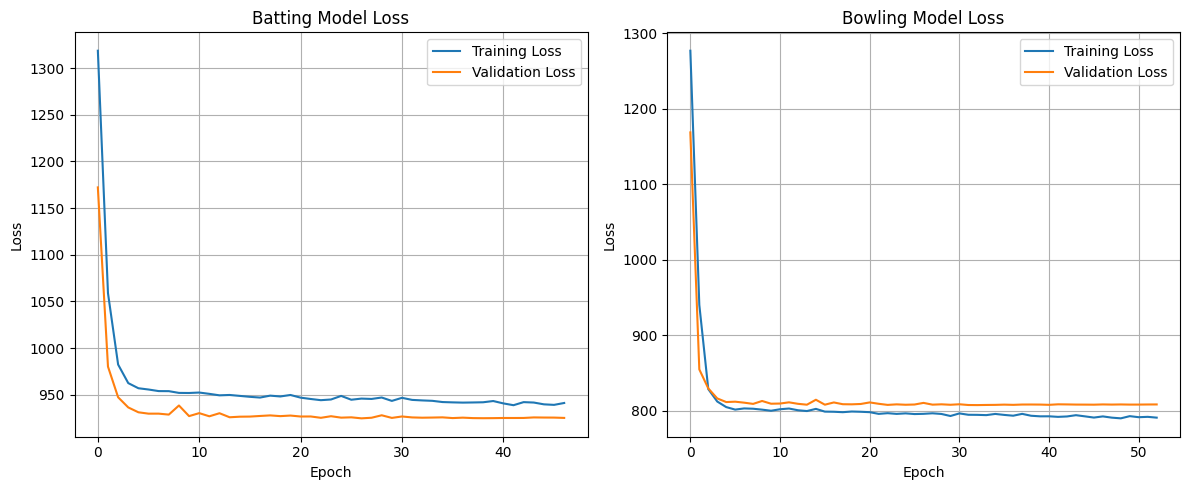

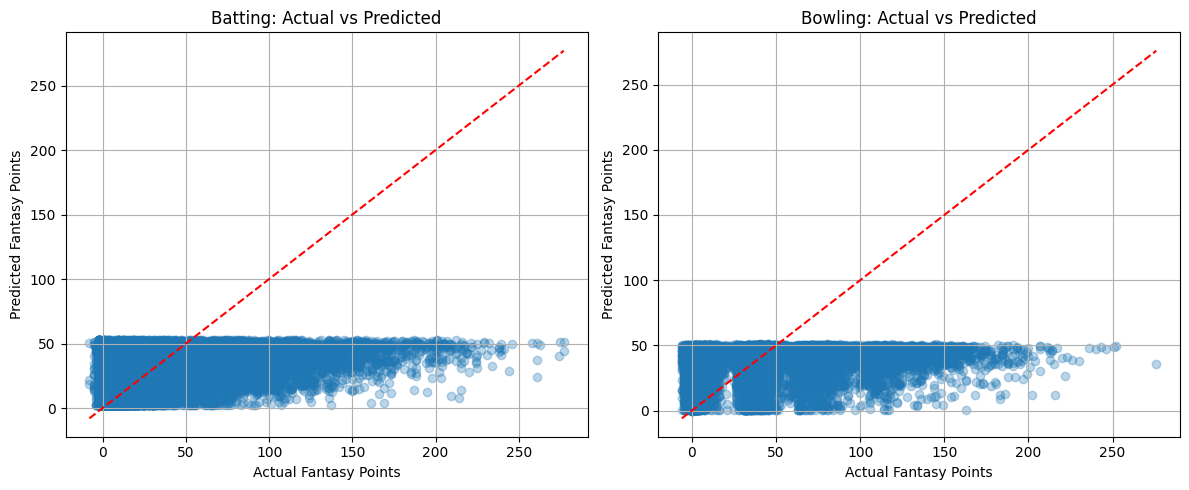

In [45]:
# Plot training and validation losses
plt.figure(figsize=(12, 5))

# Batting model
plt.subplot(1, 2, 1)
plt.plot(train_losses_bat, label='Training Loss')
plt.plot(val_losses_bat, label='Validation Loss')
plt.title('Batting Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Bowling model
plt.subplot(1, 2, 2)
plt.plot(train_losses_bowl, label='Training Loss')
plt.plot(val_losses_bowl, label='Validation Loss')
plt.title('Bowling Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('training_losses.png')
plt.show()

# Plot predictions vs actual
plt.figure(figsize=(12, 5))

# Batting predictions
plt.subplot(1, 2, 1)
plt.scatter(bat_targets, bat_preds, alpha=0.3)
plt.plot([min(bat_targets), max(bat_targets)], [min(bat_targets), max(bat_targets)], 'r--')
plt.title('Batting: Actual vs Predicted')
plt.xlabel('Actual Fantasy Points')
plt.ylabel('Predicted Fantasy Points')
plt.grid(True)

# Bowling predictions
plt.subplot(1, 2, 2)
plt.scatter(bowl_targets, bowl_preds, alpha=0.3)
plt.plot([min(bowl_targets), max(bowl_targets)], [min(bowl_targets), max(bowl_targets)], 'r--')
plt.title('Bowling: Actual vs Predicted')
plt.xlabel('Actual Fantasy Points')
plt.ylabel('Predicted Fantasy Points')
plt.grid(True)

plt.tight_layout()
plt.savefig('predictions.png')
plt.show()

In [ ]:
def predict_fantasy_points(player_data, is_batting=True):
    """
    Make predictions for new player data

    Args:
        player_data: DataFrame with player features
        is_batting: Boolean flag for batting/bowling prediction

    Returns:
        predictions: Array of predicted fantasy points
    """
    # Load the appropriate model and metadata
    if is_batting:
        model_data = torch.load('../tabTransformer/batting_model_complete.pt', map_location=device)
        encoders = joblib.load('../tabTransformer/bat_encoders.joblib')
        scaler = joblib.load('../tabTransformer/bat_scaler.joblib')
        cat_indices = model_data['cat_indices']
        num_cats = model_data['num_cats']
        feature_cols = model_data['feature_cols']

        # Initialize model
        model = TabTransformer(
            num_features=len(feature_cols),
            cat_dims=cat_indices,
            num_cats=num_cats,
            embed_dim=model_data['hyperparameters']['embed_dim'],
            hidden_dim=model_data['hyperparameters']['hidden_dim'],
            dropout=model_data['hyperparameters']['dropout'],
            n_layers=model_data['hyperparameters']['n_layers']
        ).to(device)

        # Load model weights
        model.load_state_dict(model_data['model_state_dict'])
    else:
        model_data = torch.load('../tabTransformer/bowling_model_complete.pt', map_location=device)
        encoders = joblib.load('../tabTransformer/bowl_encoders.joblib')
        scaler = joblib.load('../tabTransformer/bowl_scaler.joblib')
        cat_indices = model_data['cat_indices']
        num_cats = model_data['num_cats']
        feature_cols = model_data['feature_cols']

        # Initialize model
        model = TabTransformer(
            num_features=len(feature_cols),
            cat_dims=cat_indices,
            num_cats=num_cats,
            embed_dim=model_data['hyperparameters']['embed_dim'],
            hidden_dim=model_data['hyperparameters']['hidden_dim'],
            dropout=model_data['hyperparameters']['dropout'],
            n_layers=model_data['hyperparameters']['n_layers']
        ).to(device)

        # Load model weights
        model.load_state_dict(model_data['model_state_dict'])

    # Set model to evaluation mode
    model.eval()

    # Preprocess input data
    df = player_data.copy()

    # Handle categorical features
    for col, encoder in encoders.items():
        if col in df.columns:
            # Convert to string and handle unseen categories
            df[col] = df[col].astype(str)
            for val in df[col].unique():
                if val not in encoder.classes_:
                    print(f"Warning: Unseen category '{val}' in column '{col}'. Using default category.")
                    df.loc[df[col] == val, col] = encoder.classes_[0]

            # Transform to numerical values
            df[col] = encoder.transform(df[col])

    # Ensure all required columns are present
    for col in feature_cols:
        if col not in df.columns:
            print(f"Warning: Missing column '{col}'. Adding zeros.")
            df[col] = 0

    # Select only needed columns in the right order
    df = df[feature_cols]

    # Apply scaling to numeric features
    numeric_cols = [col for col in feature_cols if feature_cols.index(col) not in cat_indices]
    if numeric_cols:
        df[numeric_cols] = scaler.transform(df[numeric_cols])

    # Convert to tensor for prediction
    X = torch.FloatTensor(df.values).to(device)

    # Make predictions
    with torch.no_grad():
        predictions = model(X).cpu().numpy()

    return predictions